# Scatter plots, box plots and correlation matrices: sentiment and LIWC vs identity

Inputs:
- `data/results/features_to_correlate.xlsx`: one row per subject. Clinician scores (`identity_sum`, `identity_overall`, `patient_control`) and one column per `lexicon.measure` feature. The file is melted to long format before plotting.

The data in `data/` is simulated example data with 5 subjects, so the p-values here only show the pipeline works.

Outputs:
- `data/results/figures/Figure_4.pdf`, `data/results/figures/Figure_5.pdf`: manuscript figures
- `data/results/figures/de_vs_en_vader.png`, `data/results/figures/de_vs_en_liwc.png`: German vs English consistency heatmaps
- `data/results/figures/spearman_corr_german.pdf`, `data/results/figures/spearman_corr_english.pdf`: within-language correlation matrices
- `data/results/figures/<measure>_scatter.png`, `data/results/figures/<measure>_boxplot.png`: German | English pair figures, one per measure

## 1. Setup and data

- Imports and the project root (`ROOT`), found by walking up until `data/` exists.
- Load the wide file and melt it into one row per subject and feature.
- Plot settings, colours, measure titles, and the helper functions that draw each panel.

In [130]:
# ── imports ───────────────────────────────────────────────────────────────────
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from scipy.stats import pearsonr, spearmanr

# ── project root ──────────────────────────────────────────────────────────────
# Walk up from the working directory until the folder that holds "data/" is found,
# so the notebook runs whether it is opened from the root or from src/analysis/.
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

In [131]:
# ── load data ─────────────────────────────────────────────────────────────────
# features_to_correlate.xlsx is wide: one row per subject, one column per
# "<lexicon>.<measure>" feature, plus the clinical scores.
features = pd.read_excel(ROOT / "data" / "results" / "features_to_correlate.xlsx")

# wide -> long: one row per subject x feature
id_cols = ["subject_id", "patient_control", "identity_sum", "identity_overall"]
df = features.melt(id_vars=id_cols, var_name="feature", value_name="value")
df[["lexicon", "measure"]] = df["feature"].str.split(".", n=1, expand=True)
df = df.drop(columns="feature")

# German lexicons: deliwc_2015, gervader. English lexicons: vader, liwc_2022.
df["language"] = np.where(df["lexicon"].isin(["vader", "liwc_2022"]), "english", "german")

# harmonise German measure names to the English "tone" naming
german = df["language"] == "german"
df.loc[german, "measure"] = (
    df.loc[german, "measure"]
    .str.replace("emotion", "tone", regex=False)
    .str.replace("emo", "tone", regex=False)
)

df_long = df.copy()
print(df["lexicon"].unique())
display(df_long)

<StringArray>
['deliwc_2015', 'gervader', 'liwc_2022', 'vader']
Length: 4, dtype: str


,subject_id,patient_control,identity_sum,identity_overall,value,lexicon,measure,language
0,T0001,0,3,1,0.640200,deliwc_2015,negtone,german
1,T0002,0,7,3,0.130800,deliwc_2015,negtone,german
2,T0003,0,14,2,0.089400,deliwc_2015,negtone,german
3,T0004,1,22,3,0.420300,deliwc_2015,negtone,german
4,T0005,1,28,4,0.715900,deliwc_2015,negtone,german
...,...,...,...,...,...,...,...,...
230,T0001,0,3,1,0.034582,vader,valence_frequency,english
231,T0002,0,7,3,0.077253,vader,valence_frequency,english
232,T0003,0,14,2,0.059917,vader,valence_frequency,english
233,T0004,1,22,3,0.067460,vader,valence_frequency,english


In [132]:
# ── plot settings ─────────────────────────────────────────────────────────────
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 12

subs = df["subject_id"].nunique()
print(f"{subs} subjects")

# Bonferroni correction factor: the number of tests in the manuscript (74).
# Used only for the printed threshold below; the figures show raw p-values.
bonferroni = 74
alpha = 0.05
bonferroni_threshold = alpha / bonferroni  # ≈ 0.0007

# colours
teal = "#2CA68C"
blue = "#3366CC"
orange = "#ff7f0e"
purple = "#9467bd"
rose = "#cc6677"

boxplot_palette = [orange, teal, blue, purple, rose]

# patient / control colouring of the scatter plots
pc_colors_map = {0: orange, 1: blue}
pc_labels_map = {0: "Control", 1: "Patient"}

# axis titles for each measure
measure_title = {
    # Affective Instability
    'std': 'Valence Variability ',
    'diff_std': 'Valence Change Variability ',
    # Overall affective orientation
    'mean': 'Mean Valence ',
    'polarity_index': 'Polarity Index',
    'emotion_polarity_index': 'Emotion Polarity Index',
    'tone_polarity_index': 'Tone Polarity Index',
    # Degree of Negative Affect
    'neg_ratio': 'Negative Valence Frequency',
    'negemo': 'Negative Emotion Frequency',
    'negtone': 'Negative Tone Frequency',
    #'negative_mean': 'Negative Valence Intensity',
    # Degree of Positive Affect
    'pos_ratio': 'Positive Valence Frequency',
    'posemo': 'Positive Emotion Frequency',
    'postone': 'Positive Tone Frequency',
    #'positive_mean': 'Positive Valence Intensity',
    # Affectve Extremes
    'min': 'Minimum Valence',
    'max': 'Maximum Valence',
    # Emotional Density
    'hit_ratio': 'Valence Frequency',
    'emotion_frequency': 'Emotion Frequency',
    'tone_frequency': 'Tone Frequency',
    # Verbosity Controls
    'n_hits': 'Valence Word Count',
    'n_units': 'Total Word Count',
    'emotion_count': 'Emotion Word Count',
    'tone_count': 'Tone Word Count',
    # Ground Truth
    'identity_sum': 'Identity Sum Score',
    'identity_overall': 'Identity Overall Score',
}

# figures are written here
FIG_DIR = ROOT / "data" / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Bonferroni threshold: {bonferroni_threshold:.7f}")

5 subjects
Bonferroni threshold: 0.0006757


In [133]:
# ── panel helpers ─────────────────────────────────────────────────────────────
# Each figure is a 2x2 grid: scatter plots against ISS on top, box plots
# against IOS below. Every panel shows its raw (unadjusted) p-value.

def fmt_p(p):
    if p >= 0.1:
        return f"p = {p:.2f}"
    elif p >= 0.01:
        return f"p = {p:.3f}"
    elif p >= 0.0001:
        return f"p = {p:.4f}"
    else:
        return "p < 0.0001"


def add_panel_label(ax, label):
    ax.text(0.1, 0.98, label, transform=ax.transAxes, va="top", ha="right", fontsize=12, fontweight="bold")


def get_scatter_data(measure, lexicon):
    """Subject-level rows for one measure and lexicon, with ISS; None if too few."""
    dat = df[(df["measure"] == measure) & (df["lexicon"] == lexicon)][[SCATTER_TARGET, "value", "patient_control"]].dropna()
    if dat.empty or len(dat) < 3:
        return None
    dat = dat.copy()
    dat["value"] = dat["value"].astype(float)
    dat[SCATTER_TARGET] = dat[SCATTER_TARGET].astype(float)
    return dat


def get_box_data(measure, lexicon):
    """Subject-level rows for one measure and lexicon, with IOS; None if too few."""
    dat = df[(df["measure"] == measure) & (df["lexicon"] == lexicon)][[BOX_TARGET, "value", "patient_control"]].dropna()
    if dat.empty or len(dat) < 3:
        return None
    dat = dat.copy()
    dat["value"] = dat["value"].astype(float)
    dat[BOX_TARGET] = dat[BOX_TARGET].astype(float).astype(int)
    return dat


def plot_scatter_panel(ax, dat, measure, panel_label):
    """Scatter of measure against ISS, coloured by group, with Pearson r."""
    y_label = measure_title.get(measure, measure)
    legend_patches = [mpatches.Patch(color=pc_colors_map[v], label=pc_labels_map[v]) for v in pc_colors_map]

    ax.scatter(dat[SCATTER_TARGET], dat["value"], c=dat["patient_control"].map(pc_colors_map), alpha=0.7, s=30, edgecolors="none")
    sns.regplot(x=dat[SCATTER_TARGET], y=dat["value"], scatter=False, line_kws={"color": "black", "linestyle": "--", "linewidth": 1.0}, ci=95, ax=ax)

    r, p = pearsonr(dat[SCATTER_TARGET], dat["value"])
    print(f"{panel_label} {measure} vs ISS: r = {r:.4f}, p = {p:.10f}")

    ax.set_xlabel("Identity Sum Score (ISS)")
    ax.set_ylabel(y_label)
    ax.set_title("")
    add_panel_label(ax, panel_label)

    ax.text(0.98, 0.98, f"r = {r:.2f}, {fmt_p(p)}", transform=ax.transAxes, va="top", ha="right", fontsize=12)

    ax.set_xlim(-1, 31)
    ymin, ymax = dat["value"].min(), dat["value"].max()
    yrange = ymax - ymin if ymax != ymin else 1
    ax.set_ylim(ymin - 0.15 * yrange, ymax + 0.15 * yrange)

    ax.grid(True, which="both", alpha=0.5, ls="--")
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(n=2))

    loc = "lower left" if r < 0 else "lower right"
    ax.legend(handles=legend_patches, loc=loc, frameon=True, ncols=1, fontsize=11)


def plot_box_panel(ax, dat, measure, panel_label):
    """Box plot of measure by IOS score, with Spearman rho. Small groups are shown as points."""
    y_label = measure_title.get(measure, measure)

    counts = dat[BOX_TARGET].value_counts()
    large_cats = counts[counts >= min_samples].index
    small_cats = counts[counts < min_samples].index
    x_levels = sorted(dat[BOX_TARGET].unique())

    bp = sns.boxplot(x=BOX_TARGET, y="value", data=dat[dat[BOX_TARGET].isin(large_cats)], order=x_levels, hue=BOX_TARGET, palette=boxplot_palette, legend=False, ax=ax)

    for patch in bp.patches:
        fc = patch.get_facecolor()
        patch.set_facecolor((fc[0], fc[1], fc[2], 0.7))

    for cat in small_cats:
        sdf = dat[dat[BOX_TARGET] == cat]
        x_pos = list(x_levels).index(cat)
        jx = [x_pos + 0.05 * (i - len(sdf) / 2) for i in range(len(sdf))]
        ax.scatter(jx, sdf["value"], color=rose, edgecolors="black", alpha=0.7, s=40, zorder=10)

    rho, p = spearmanr(dat["value"], dat[BOX_TARGET])
    print(f"{panel_label} {measure} vs IOS: rho = {rho:.4f}, p = {p:.10f}")

    ax.set_xlabel("Identity Overall Score (IOS)")
    ax.set_ylabel(y_label)
    ax.set_title("")
    add_panel_label(ax, panel_label)

    ax.text(0.98, 0.98, f"ρ = {rho:.2f}, {fmt_p(p)}", transform=ax.transAxes, va="top", ha="right", fontsize=12)

    ymin, ymax = dat["value"].min(), dat["value"].max()
    yrange = ymax - ymin if ymax != ymin else 1
    ax.set_ylim(ymin - 0.15 * yrange, ymax + 0.15 * yrange)

    ax.grid(True, which="both", alpha=0.5, ls="--")
    ax.yaxis.set_minor_locator(AutoMinorLocator(n=2))

## 2. Manuscript figures 4 and 5

Each figure is a 2×2 grid. The top row has scatter plots against the Identity Sum Score (ISS), with Pearson r. The bottom row has box plots against the Identity Overall Score (IOS), with Spearman rho. Every panel shows the raw (unadjusted) p-value.

- **Figure 4:** Valence Variability and Valence Change Variability (VADER).
- **Figure 5:** Mean Valence (VADER) and Tone Polarity Index (LIWC-22). VADER has no tone measure, so the right column uses LIWC-22. The caption names the Tone Polarity Index, so this choice follows the caption.

In [134]:
# ── figure builder ────────────────────────────────────────────────────────────
SCATTER_TARGET = "identity_sum"
BOX_TARGET = "identity_overall"
min_samples = 5  # IOS levels with fewer subjects are shown as points, not boxes


def make_figure(fig_name, left, right):
    """Draw a 2x2 figure and save it to data/results/figures/<fig_name>.

    left and right are (measure, lexicon) tuples for the left and right columns.
    """
    left_scatter = get_scatter_data(*left)
    right_scatter = get_scatter_data(*right)
    left_box = get_box_data(*left)
    right_box = get_box_data(*right)

    if all(x is None for x in [left_scatter, right_scatter, left_box, right_box]):
        raise ValueError(f"No valid data for {fig_name}.")

    fig, axes = plt.subplots(2, 2, figsize=(8, 5.3))

    panels = [
        (axes[0, 0], left_scatter, left[0], plot_scatter_panel, "(a)"),
        (axes[0, 1], right_scatter, right[0], plot_scatter_panel, "(b)"),
        (axes[1, 0], left_box, left[0], plot_box_panel, "(c)"),
        (axes[1, 1], right_box, right[0], plot_box_panel, "(d)"),
    ]
    for ax, dat, measure, plot, label in panels:
        if dat is None:
            ax.set_visible(False)
        else:
            plot(ax, dat, measure, label)

    plt.subplots_adjust(wspace=0.35, hspace=0.35)
    plt.savefig(FIG_DIR / fig_name)
    plt.show()
    plt.close()

(a) std vs ISS: r = 0.8234, p = 0.0866748180
(b) diff_std vs ISS: r = 0.7129, p = 0.1765083122
(c) std vs IOS: rho = 0.4104, p = 0.4925357817
(d) diff_std vs IOS: rho = 0.3078, p = 0.6143840028


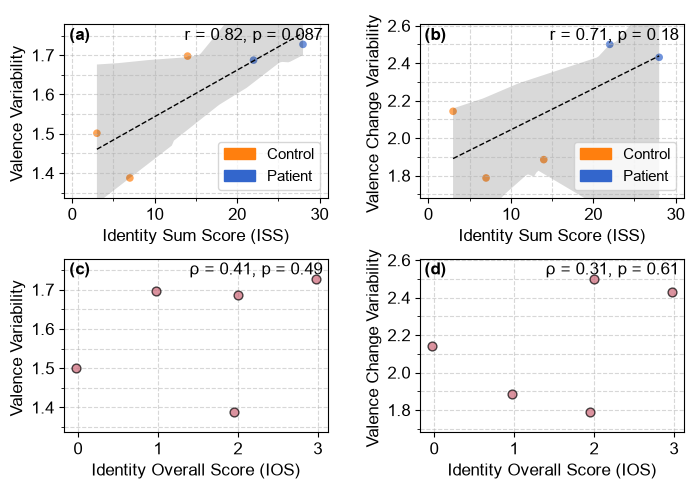

In [135]:
# ── Figure 4: affective variability vs identity diffusion ─────────────────────
# Left: Valence Variability. Right: Valence Change Variability. Both VADER.
make_figure(
    "Figure_4.pdf",
    left=("std", "vader"),
    right=("diff_std", "vader"),
)

(a) mean vs ISS: r = -0.0026, p = 0.9967105251
(b) tone_polarity_index vs ISS: r = 0.1866, p = 0.7637555187
(c) mean vs IOS: rho = 0.4104, p = 0.4925357817
(d) tone_polarity_index vs IOS: rho = -0.3078, p = 0.6143840028


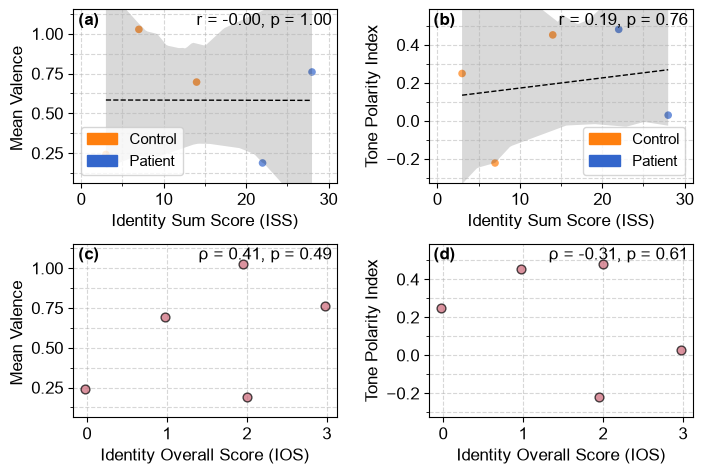

In [136]:
# ── Figure 5: overall affective orientation vs identity diffusion ─────────────
# Left: Mean Valence (VADER). Right: Tone Polarity Index (LIWC-22). VADER has no
# tone measures, so the right panels use the LIWC-22 feature.
make_figure(
    "Figure_5.pdf",
    left=("mean", "vader"),
    right=("tone_polarity_index", "liwc_2022"),
)

## 3. German vs English consistency

For each measure shared by a German and an English lexicon, Spearman r is computed across subjects. Each heatmap shows one row per measure.

- `de_vs_en_vader.png`: GerVADER vs VADER.
- `de_vs_en_liwc.png`: DELIWC-2015 vs LIWC-22.

In [137]:
# ── measure groups (ordering for the heatmaps) ───────────────────────────────
measure_groups = {
    "Affective Variability": ["std", "diff_std"],
    "Overall Affective Orientation": ["mean", "polarity_index", "emotion_polarity_index", "tone_polarity_index"],
    "Negative Affect Usage": ["neg_ratio", "negemo", "negtone"],
    "Positive Affect Usage": ["pos_ratio", "posemo", "postone"],
    "Affective Extremes": ["min", "max"],
    "Affective Expressiveness": ["hit_ratio", "emotion_frequency", "tone_frequency"],
    "Verbosity Controls": ["n_hits", "n_units", "emotion_count", "tone_count"],
}

ordered_measures = [measure for group in measure_groups.values() for measure in group]

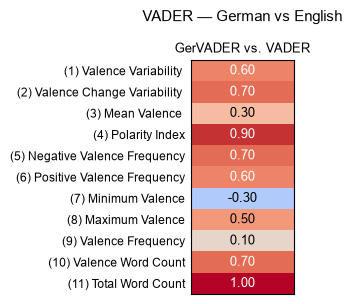

Saved /Users/katra/Library/Mobile Documents/com~apple~CloudDocs/sentiment_paper/data/results/figures/de_vs_en_vader.png


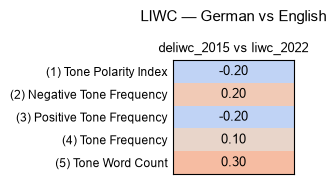

Saved /Users/katra/Library/Mobile Documents/com~apple~CloudDocs/sentiment_paper/data/results/figures/de_vs_en_liwc.png


In [138]:
# ── German vs English consistency heatmaps ───────────────────────────────────
def compute_de_en_r(df, lex_de, lex_en):
    """Spearman r between the German and English lexicon for each shared measure."""
    pivot_de = df[(df["language"] == "german") & (df["lexicon"] == lex_de)].pivot_table(
        index="subject_id", columns="measure", values="value"
    )
    pivot_en = df[(df["language"] == "english") & (df["lexicon"] == lex_en)].pivot_table(
        index="subject_id", columns="measure", values="value"
    )

    common_subjects = pivot_de.index.intersection(pivot_en.index)
    if len(common_subjects) < 3:
        return {}

    pivot_de = pivot_de.loc[common_subjects]
    pivot_en = pivot_en.loc[common_subjects]

    results = {}
    common_measures = pivot_de.columns.intersection(pivot_en.columns)
    for m in common_measures:
        a = pivot_de[m].values
        b = pivot_en[m].values
        mask = ~np.isnan(a) & ~np.isnan(b)
        if mask.sum() > 2:
            r, p = spearmanr(a[mask], b[mask])
            results[m] = (r, p)
    return results


def plot_consistency_heatmap_multi(df, columns, ordered_measures,
                                    measure_title, fname="out.png", title=""):
    """One heatmap column per (label, German lexicon, English lexicon) entry in columns."""
    data = {}
    all_measures = set()
    for col_label, lex_de, lex_en in columns:
        key = (col_label, lex_de, lex_en)
        data[key] = compute_de_en_r(df, lex_de, lex_en)
        all_measures.update(data[key].keys())

    cols_ordered = [m for m in ordered_measures if m in all_measures]
    n = len(cols_ordered)
    n_cols = len(columns)

    r_mat = np.full((n, n_cols), np.nan)
    for ci, col in enumerate(columns):
        key = col
        for ri, m in enumerate(cols_ordered):
            if m in data[key]:
                r_mat[ri, ci], _ = data[key][m]

    fig_w = 2.5 + n_cols * 0.7
    fig_h = n * 0.2 + 1.
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    ax.imshow(r_mat, cmap="coolwarm", norm=norm, aspect="auto")

    for ri in range(n):
        for ci in range(n_cols):
            v = r_mat[ri, ci]
            if np.isnan(v):
                continue
            tc = "white" if abs(v) > 0.55 else "black"
            ax.text(ci, ri, f"{v:.2f}", ha="center", va="center",
                    fontsize=9, color=tc)

    y_labels = [f"({i+1}) {measure_title.get(m, m)}" for i, m in enumerate(cols_ordered)]
    ax.set_yticks(range(n))
    ax.set_yticklabels(y_labels, fontsize=8.5)
    ax.tick_params(axis="y", length=0, pad=4)

    ax.set_xticks(range(n_cols))
    ax.set_xticklabels([col[0] for col in columns], fontsize=9)
    ax.tick_params(axis="x", length=0)
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")

    ax.set_title(title, fontsize=11, pad=28)

    plt.tight_layout()
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {fname}")


# VADER
plot_consistency_heatmap_multi(
    df_long,
    columns=[
        ("GerVADER vs. VADER", "gervader", "vader"),
    ],
    ordered_measures=ordered_measures,
    measure_title=measure_title,
    fname=FIG_DIR / "de_vs_en_vader.png",
    title="VADER — German vs English",
)

# LIWC
plot_consistency_heatmap_multi(
    df_long,
    columns=[
        ("deliwc_2015 vs liwc_2022", "deliwc_2015", "liwc_2022"),
    ],
    ordered_measures=ordered_measures,
    measure_title=measure_title,
    fname=FIG_DIR / "de_vs_en_liwc.png",
    title="LIWC — German vs English",
)

## 4. Within-language correlation matrices

Spearman correlations between all measures, computed separately for the German and English lexicons. Each matrix is saved as a PDF.

In [ ]:
# ── within-language correlation matrices ─────────────────────────────────────
# Spearman correlations between all measures, computed separately for the
# German and the English lexicons.
for lang in ["german", "english"]:
    fig, ax = plt.subplots(1, 1, figsize=(10, 8))

    sub = df[df["language"] == lang]
    pivot = sub.pivot_table(index="subject_id", columns="measure", values="value")

    cols = [m for m in ordered_measures if m in pivot.columns]
    pivot = pivot[cols]
    n = len(cols)

    corr, _ = spearmanr(pivot.values, nan_policy="omit")
    if n == 2:
        corr = np.array([[1, corr], [corr, 1]])
    corr = pd.DataFrame(corr, index=cols, columns=cols)

    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    im = ax.imshow(corr.values, cmap="coolwarm", norm=norm, aspect="auto")

    y_labels = [f"({i+1}) {measure_title.get(m, m)}" for i, m in enumerate(cols)]
    ax.set_yticks(range(n))
    ax.set_yticklabels(y_labels, fontsize=10)
    ax.tick_params(axis="y", length=0, pad=4)

    ax.set_xticks(range(n))
    ax.set_xticklabels([f"({i+1})" for i in range(n)], fontsize=10)
    ax.tick_params(axis="x", length=0)

    for i in range(n):
        for j in range(n):
            v = corr.values[i, j]
            tc = "white" if abs(v) > 0.55 else "black"
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=10, color=tc, fontweight="500")

    cbar = fig.colorbar(im, ax=ax, fraction=0.015, pad=0.02)
    cbar.set_label("Spearman r", fontsize=11)
    cbar.set_ticks([-1, -0.5, 0, 0.5, 1])

    ax.set_title(lang.capitalize(), fontsize=12, pad=10)

    plt.tight_layout()
    plt.savefig(FIG_DIR / f"spearman_corr_{lang}.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

## 5. German vs English scatter and box pairs

One figure per measure, with the German lexicon on the left and the English lexicon on the right. Each measure has at most one lexicon per language, so each panel is unique.

- Scatter pairs show the measure against ISS, with Bonferroni-adjusted Pearson r.
- Box pairs show the measure by IOS, with Bonferroni-adjusted Spearman r. Groups with fewer than 5 subjects are drawn as points, not boxes.

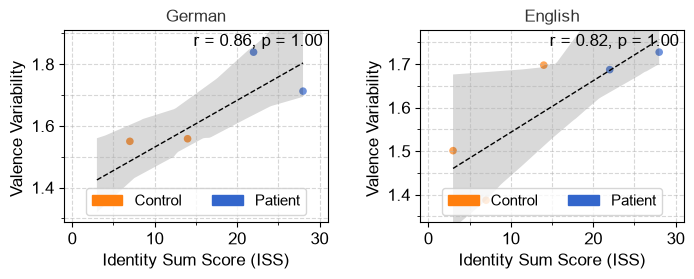

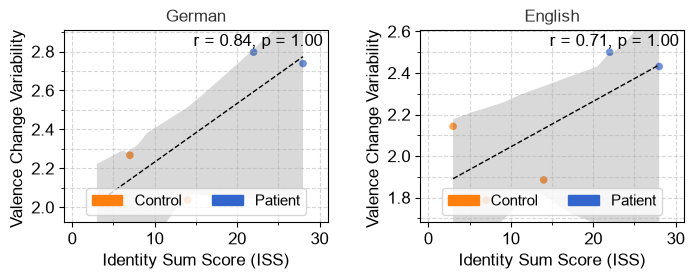

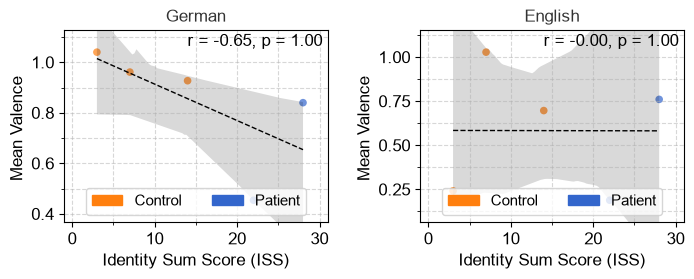

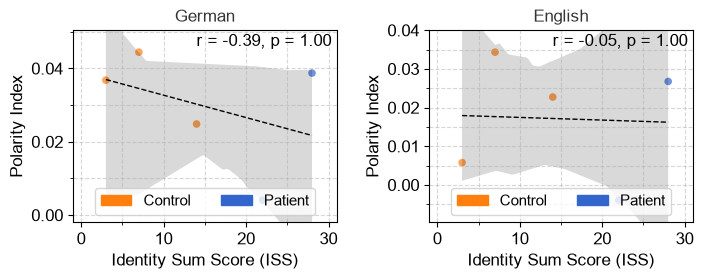

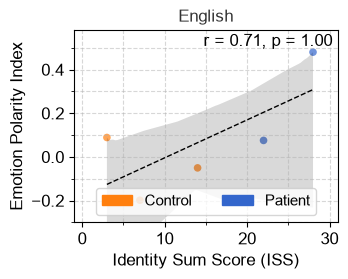

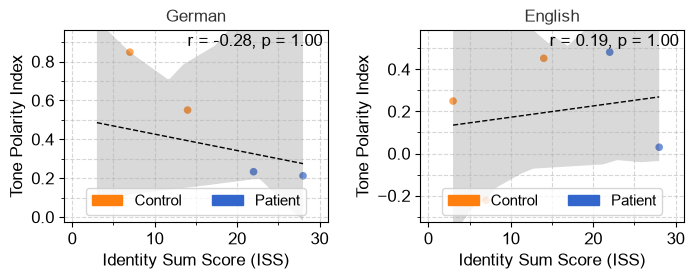

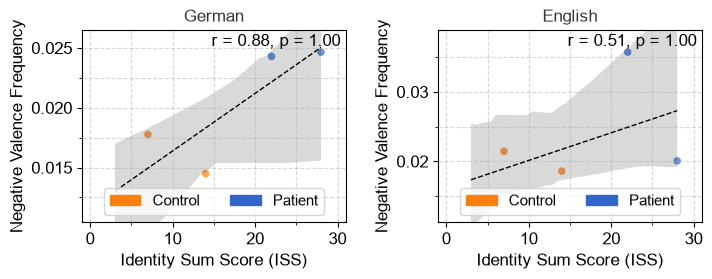

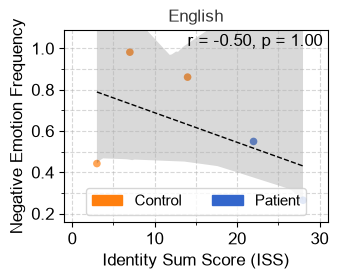

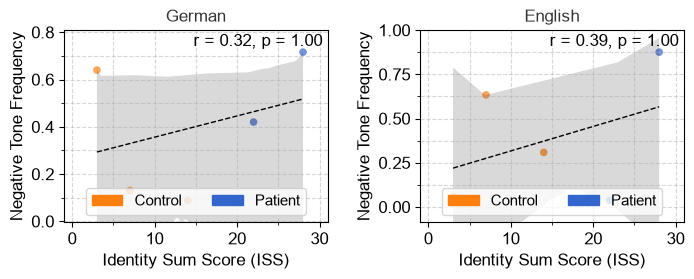

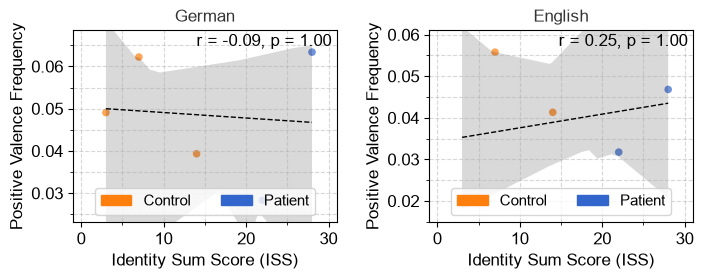

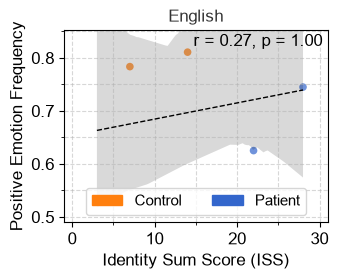

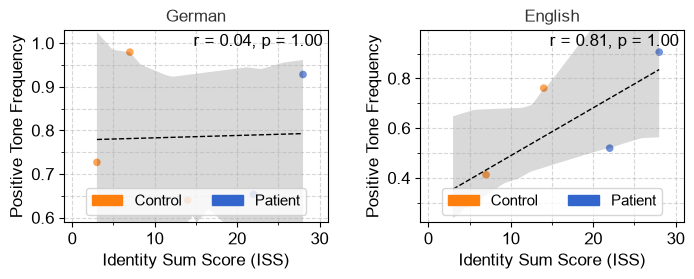

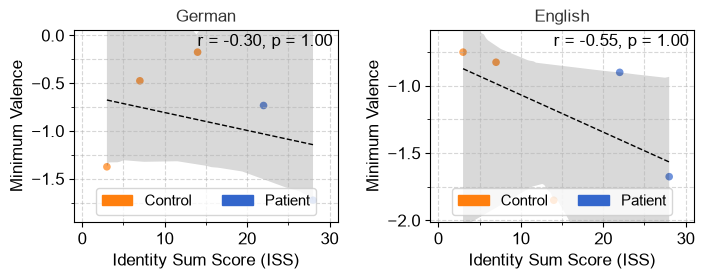

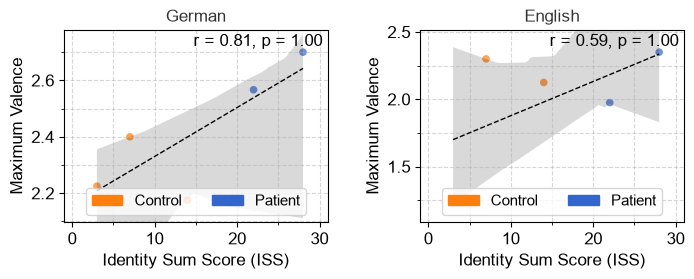

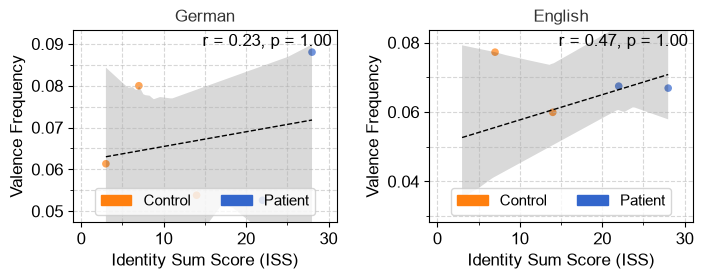

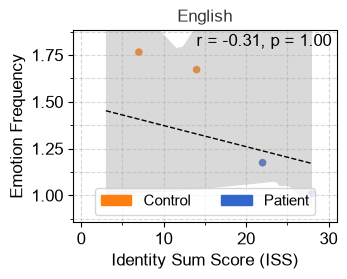

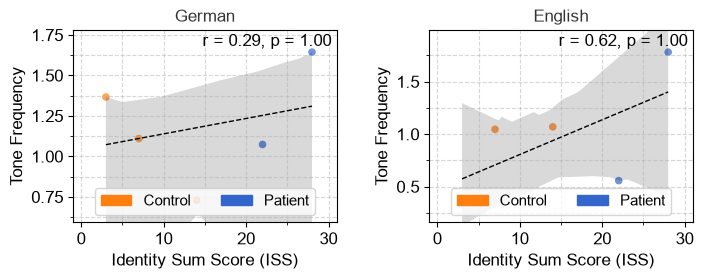

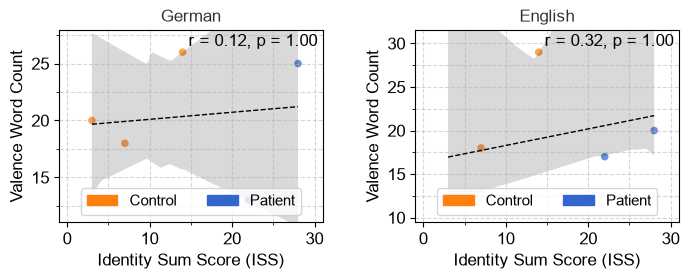

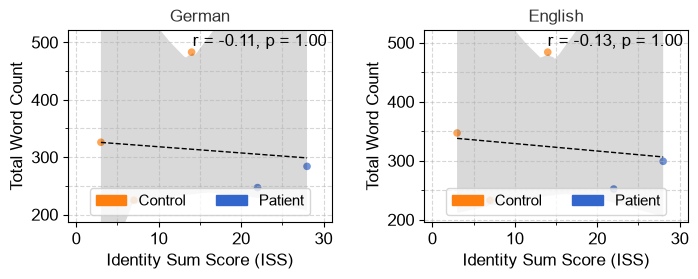

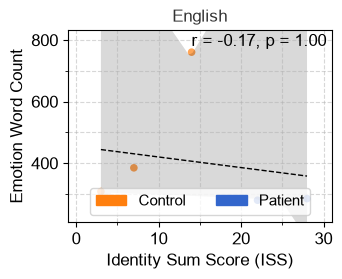

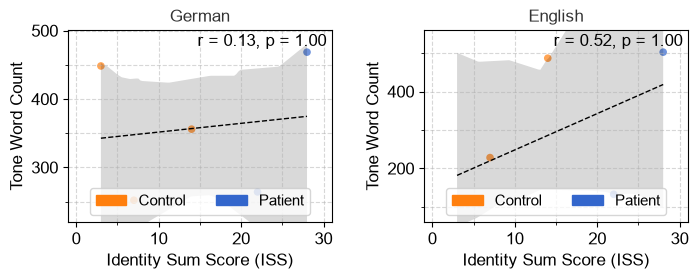

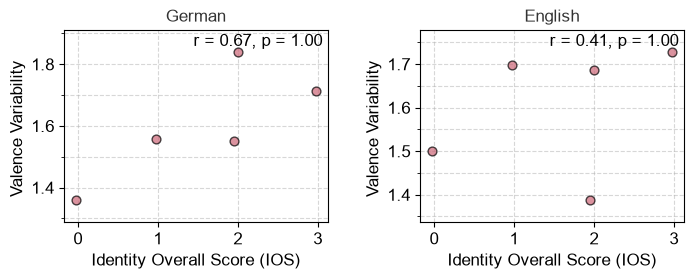

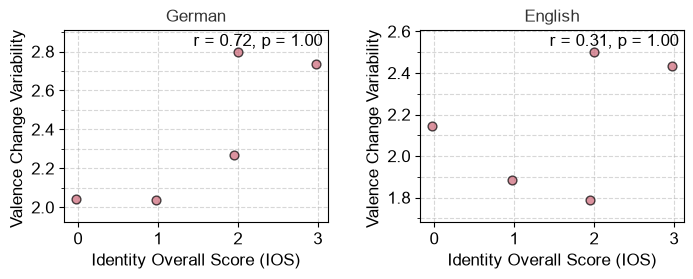

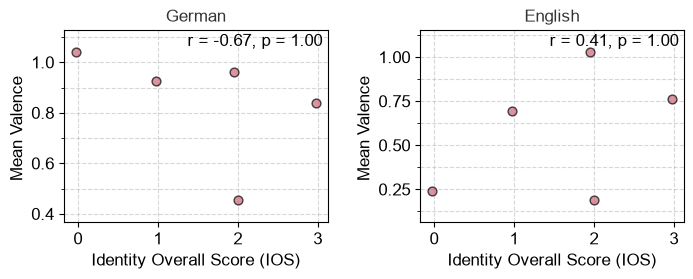

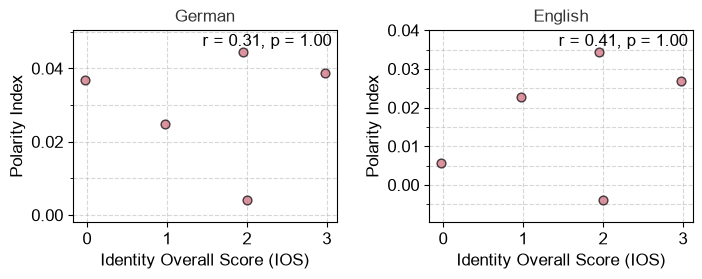

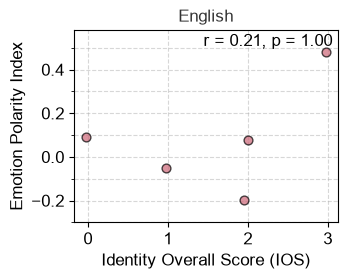

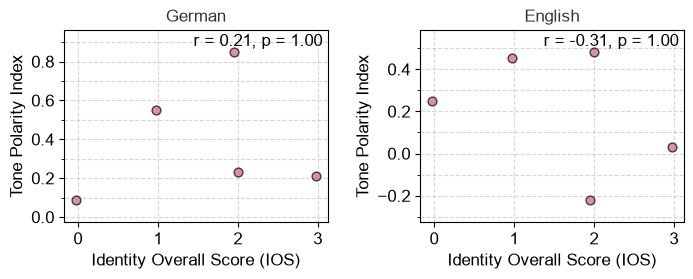

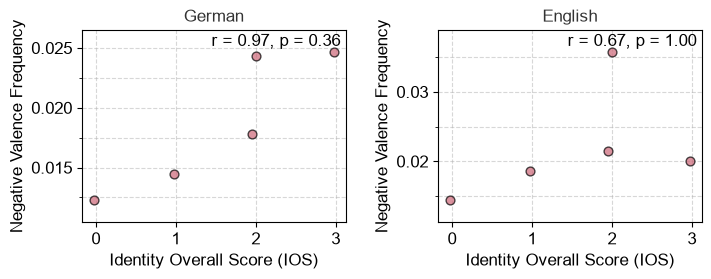

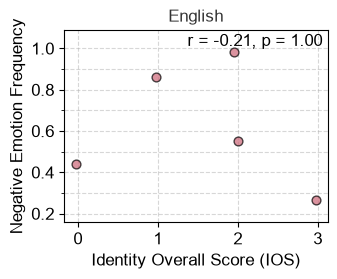

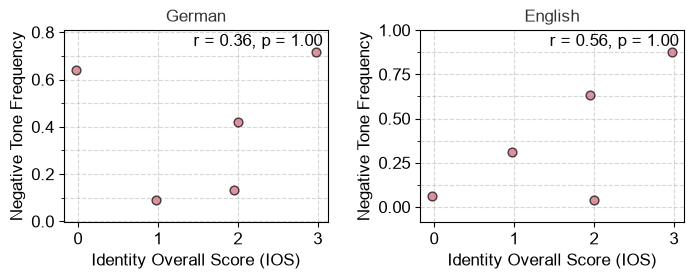

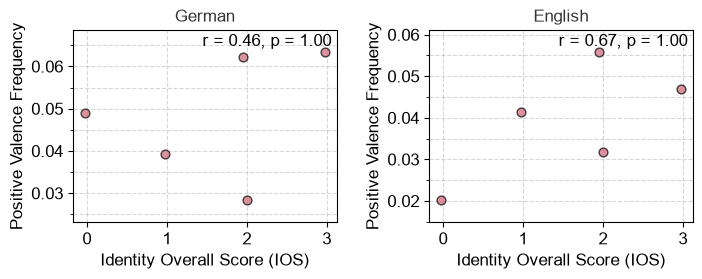

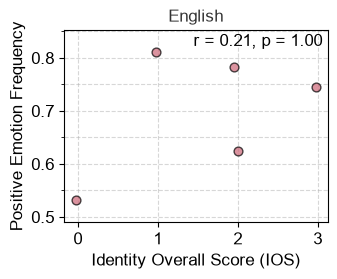

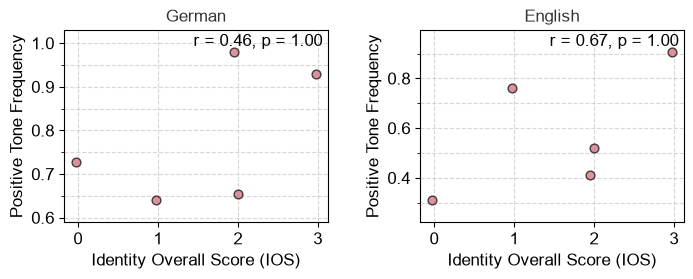

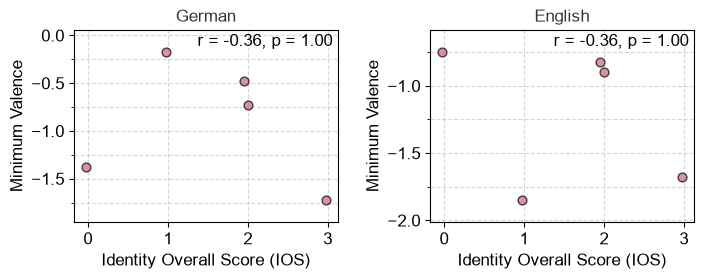

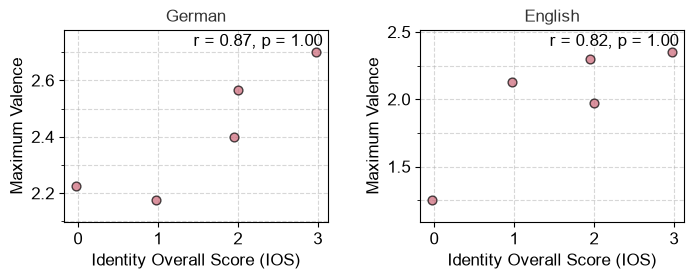

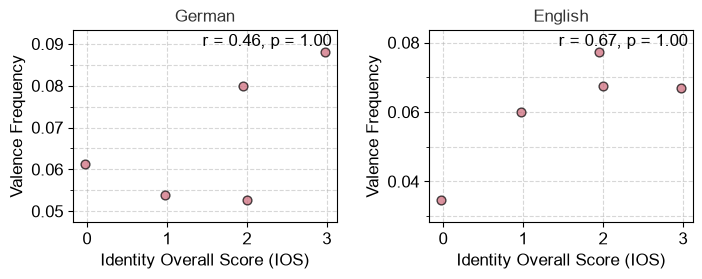

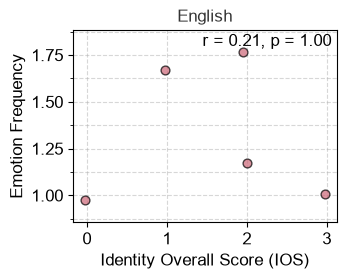

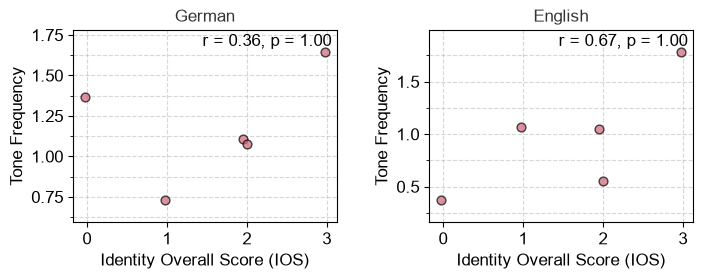

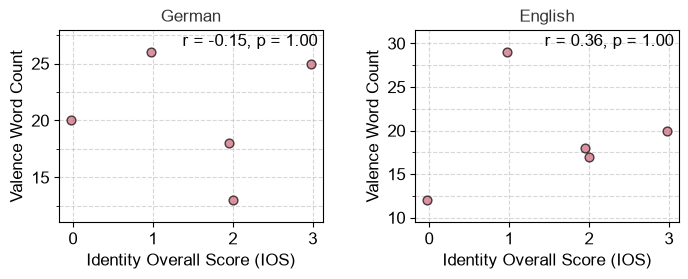

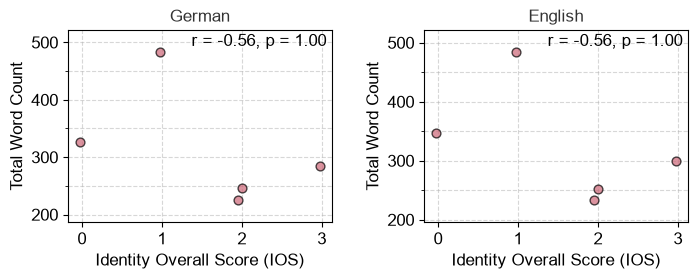

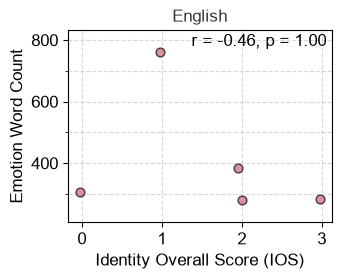

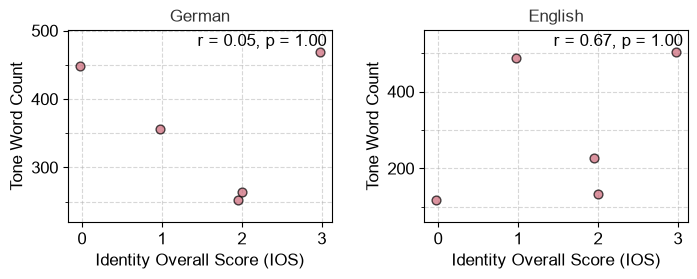

In [ ]:
# ── German vs English pairs: scatter and box plots ───────────────────────────
# One figure per measure: the German lexicon on the left, the English one on the
# right. Each measure has at most one lexicon per language, so each panel is unique.


def plot_pair_panel(ax, dat, measure, title):
    """Scatter of measure against ISS, coloured by group, with Bonferroni-adjusted r."""
    legend_patches = [mpatches.Patch(color=pc_colors_map[v], label=pc_labels_map[v]) for v in pc_colors_map]

    ax.scatter(dat[SCATTER_TARGET], dat["value"], c=dat["patient_control"].map(pc_colors_map), alpha=0.7, s=30, edgecolors="none")
    sns.regplot(x=dat[SCATTER_TARGET], y=dat["value"], scatter=False, line_kws={"color": "black", "linestyle": "--", "linewidth": 1.0}, ci=95, ax=ax)

    r, p = pearsonr(dat[SCATTER_TARGET], dat["value"])
    p_adj = min(p * bonferroni, 1.0)

    ax.set_xlabel("Identity Sum Score (ISS)")
    ax.set_ylabel(measure_title.get(measure, measure))
    ax.set_title(title, fontsize=12, alpha=0.8)
    ax.text(0.98, 0.98, f"r = {r:.2f}, {fmt_p(p_adj)}", transform=ax.transAxes, va="top", ha="right", fontsize=12)

    ax.set_xlim(-1, 31)
    ymin, ymax = dat["value"].min(), dat["value"].max()
    yrange = ymax - ymin if ymax != ymin else 1
    ax.set_ylim(ymin - 0.15 * yrange, ymax + 0.15 * yrange)

    ax.grid(True, which="both", alpha=0.5, ls="--")
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(n=2))
    ax.legend(handles=legend_patches, loc="lower center", frameon=True, ncols=2, fontsize=11)


def plot_box_pair_panel(ax, dat, measure, title):
    """Box plot of measure by IOS, with Bonferroni-adjusted Spearman r. Small IOS groups are shown as points."""
    counts = dat[BOX_TARGET].value_counts()
    large_cats = counts[counts >= min_samples].index
    small_cats = counts[counts < min_samples].index
    x_levels = sorted(dat[BOX_TARGET].unique())

    bp = sns.boxplot(x=BOX_TARGET, y="value", data=dat[dat[BOX_TARGET].isin(large_cats)], order=x_levels, hue=BOX_TARGET, palette=boxplot_palette, legend=False, ax=ax)
    for patch in bp.patches:
        fc = patch.get_facecolor()
        patch.set_facecolor((fc[0], fc[1], fc[2], 0.7))

    for cat in small_cats:
        sdf = dat[dat[BOX_TARGET] == cat]
        x_pos = list(x_levels).index(cat)
        jx = [x_pos + 0.05 * (i - len(sdf) / 2) for i in range(len(sdf))]
        ax.scatter(jx, sdf["value"], color=rose, edgecolors="black", alpha=0.7, s=40, zorder=10)

    r, p = spearmanr(dat["value"], dat[BOX_TARGET])
    p_adj = min(p * bonferroni, 1.0)

    ax.set_xlabel("Identity Overall Score (IOS)")
    ax.set_ylabel(measure_title.get(measure, measure))
    ax.set_title(title, fontsize=12, alpha=0.8)
    ax.text(0.98, 0.98, f"r = {r:.2f}, {fmt_p(p_adj)}", transform=ax.transAxes, va="top", ha="right", fontsize=12)

    ymin, ymax = dat["value"].min(), dat["value"].max()
    yrange = ymax - ymin if ymax != ymin else 1
    ax.set_ylim(ymin - 0.15 * yrange, ymax + 0.15 * yrange)

    ax.grid(True, which="both", alpha=0.5, ls="--")
    ax.yaxis.set_minor_locator(AutoMinorLocator(n=2))


def save_language_pairs(get_data, plot_panel, out_dir, kind):
    """One German | English figure per measure, saved to out_dir as <measure>_<kind>.png."""
    out_dir.mkdir(parents=True, exist_ok=True)

    for measure in [m for m in ordered_measures if m in set(df["measure"])]:
        # lexicon used for this measure in each language (one per language)
        lex_by_lang = df[df["measure"] == measure].groupby("language")["lexicon"].first()

        fig, axes = plt.subplots(1, 2, figsize=(8, 2.5))
        any_plotted = False

        for ax, lang in zip(axes, ["german", "english"]):
            dat = get_data(measure, lex_by_lang[lang]) if lang in lex_by_lang else None
            if dat is None:
                ax.set_visible(False)
                continue
            plot_panel(ax, dat, measure, lang.capitalize())
            any_plotted = True

        if not any_plotted:
            plt.close()
            continue

        plt.subplots_adjust(wspace=0.35)
        plt.savefig(out_dir / f"{measure}_{kind}.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()


save_language_pairs(get_scatter_data, plot_pair_panel, FIG_DIR, "scatter")
save_language_pairs(get_box_data, plot_box_pair_panel, FIG_DIR, "boxplot")